In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [4]:
from classes import *
from functions import *
from utils import *
from metrics import *
import seaborn as sns
import statsmodels.tsa as sm
import statsmodels.api as sma
import matplotlib.pyplot as plt
import pickle
import warnings
%load_ext autoreload
%autoreload 2
pd.set_option('display.max_columns', None)

## 0. Le modèle et ses grandeurs


Le modèle s'écrit :

\begin{align}
&\epsilon_t = \sigma_t\eta_t\\
&\sigma_t^2 = \omega(\Delta_t)+\sum_{i=1}^q\alpha_i(\Delta_t)\epsilon_{t-i}^2{+\sum_{j=1}^k\mu_j(\Delta_t)|x_{j,t-1}|}\\
&P(\Delta_{t}=j|\Delta_{t-1}=i,\mathcal{O}_t) = P(i,j){\times\frac{\exp(\beta_{ij}'X_{t-1})}{\sum_{l=1}^dp_0(i,l)\exp(\beta_{il}'X_{t-1})}}
\end{align}

Avec:
- $\Delta_t$ la chaîne de markov, qui comprend $d$ états
- $\epsilon_t$ le processus (correspond aux rendements qu'on veut modéliser)
- $X_t$ la (ou les) variable(s) exogène(s)

Les paramètres sont:
- $\alpha$, qui est de shape $(q*d)
- $\omega$, qui est de shape $d$
- exogen_additive et exogen_transition (qui correspondent respectivement aux exogènes à mettre dans les deux équations du modèle, même si ils ne sont pas séparés dans l'écriture initiale), additive correspond à l'équation 2 et transition à l'équation 3,\
les deux sont de shape $(n*k)$, avec $k$ le nombre d'exogènes, et $n$ la taile du sample. plus précisément exogen_additive est de shape $(n*k_{add})$, et exogen_transition de shape $(n*k_{trans})$. mais pour l'instant je n'ai jamais distingué les deux $k$
shape
- $\mu$, qui est de shape $(k_{add},d)$
- $\beta$ qui est de shape $(d,d,k_{trans})
- $P$ qui est de shape $(d,d)$

# 1. La classe MS_ARCH
Input : un dictionnaire, qui doit contenir:
- $\alpha$
- $P$
- $\pi_0$, les probabilités initiales de la chaîne de markov, pas important non plus

et (optionnels);
- exogen_additive et exogen_transition
- $\beta$ (si il y a exogen transition)
- $\mu$ (si il y a exogen additive)
- 'transition_f', ne t'en occupe pas, pas important

Tu peux ensuite utiliser model.simulate pour générer un échantillon via les paramètres que tu as spécifié. dans l'exemple np.random.seed force la séquence aléatoire à être la même\
 (utile pour reproduire les résultats), tu peux la retirer si tu veux des résultats différents à chaque fois.\
 Tu peux ensuite trouver les résultats dans les attributs de model, le plus important étant ta série de $\epsilon$ générée, que tu as via model.eps


In [3]:
np.random.seed(5)
sample_size = 10000

true_params =  {'alpha':np.array([[0.2,0.4],[0.8,0.1]]),\
               'P': np.array([[0.98,0.02],[0.01,0.99]]),\
               'omega':np.array([0.2,0.8]),\
               #'exogen_transition' : np.random.uniform(0,1,size=(sample_size)).reshape(-1,1),\
               'beta' : np.array([[[-0.1,0],[0.1,0]],[[0.5,0],[-0.5,0]]]).reshape(2,2,2),\
               'mu' : np.array([[0.4,0],[0,0.5]]),\
               'exogen_additive' : abs(AR([0.9,0.08],length=sample_size*2)).reshape(sample_size,2),\
               'exogen_transition' : AR([0.9,0.08],length=sample_size*2).reshape(sample_size,2),\
               'transition_f' : 'soft-exp',\
               #'seed' : 5,\
                "pi_0":np.array([0.5,0.5])}

[-0.40270129  1.37667462  0.29406213 ... -0.95714292  1.7898269
  1.35395473]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 

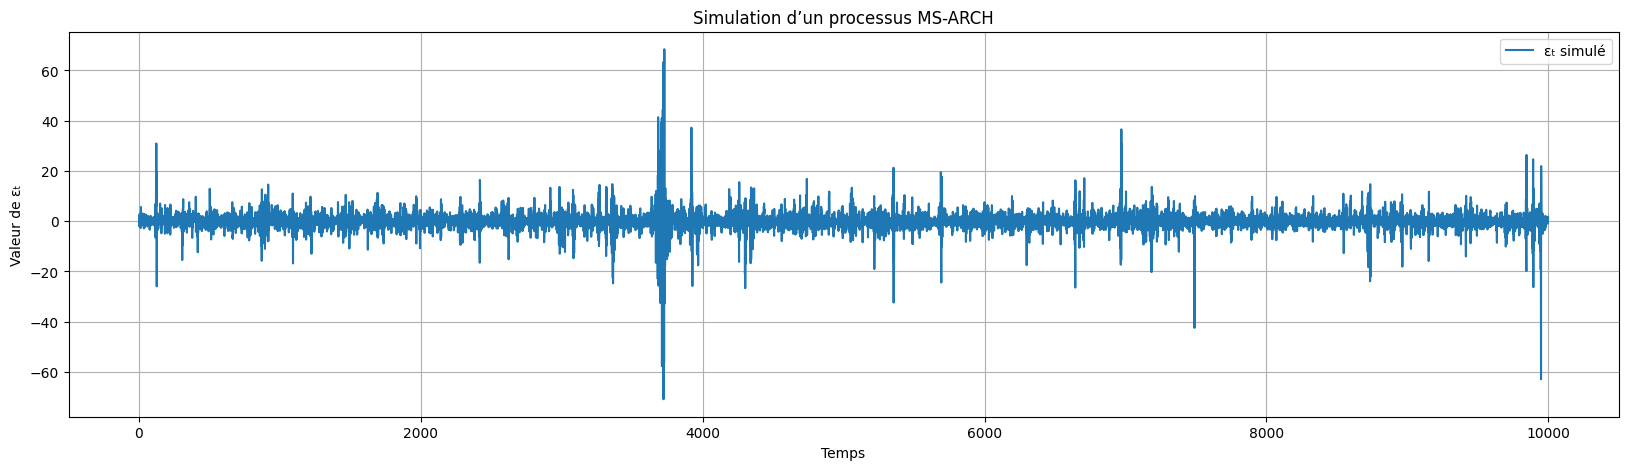

In [4]:
model = MS_ARCH(true_params=true_params)
model.simulate(length=sample_size)
#true_params['log-likelihood'] = compute_log_likelihood(model.eps,true_params)
print(model.eps)
print(model.states)
states = np.array(model.states)
print("Régime 0 :", np.sum(states == 0))
print("Régime 1 :", np.sum(states == 1))

plt.figure(figsize=(20, 5))
plt.plot(model.eps, label="εₜ simulé")
plt.title("Simulation d’un processus MS-ARCH")
plt.xlabel("Temps")
plt.ylabel("Valeur de εₜ")
plt.legend()
plt.grid(True)
plt.show()




# 2. La fonction de calibration MS_EM_algorithm
Input : 
1. ta série (epsilon), un array d'une dimension

2. un dictionnaire de paramètres initiaux, qui doit contenir (same que pour le 1. + le $\lambda$):
- $\alpha$
- $P$
- $\pi_0$, les probabilités initiales de la chaîne de markov, pas important non plus

et (optionnels);
- exogen_additive et exogen_transition
- $\beta$ (si il y a exogen transition)
- $\mu$ (si il y a exogen additive)
- 'transition_f', ne t'en occupe pas, pas important
- $\lambda$ le paramètre de pénalisation correspondant à la méthode LASSO, si tu ne le spécifie pas il vaut $0$ par défaut, donc pas besoin de t'en occuper sauf si tu veux utiliser la méthode LASSO

3. le nombre d'itérations (niter), souvent niter=200 suffit, voire moins, mais ça m'arrive de prendre niter=1000 pour être tranquille.

Tu peux ensuite utiliser MS_EM_algorithm pour calibrer ton modèle, le résultat est un dictionnaire, chaque clé correspond à une itération, donc ton résultat final correspond à result[niter], result[0] comprend les conditions initiales. Les paramètres n'étant pas update\
(exogen_transition, exogen_additive, lambda) ne sont pas dans les result[i] sauf dans result[0].

In [ ]:
initial_params =    {'pi_0' : np.array([0.5,0.5]),\
                    'omega' : np.array([0.3,0.7]),\
                    'P' : np.ones((2,2))/2,\
                    'alpha' : np.array([[0,0],[0,0]]),\
                    'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    #'transition_f' : 'soft-exp',\
                    'beta' : np.zeros((2,2,2)),\
                    'beta_constraint' : 'general',\
                    'mu' : np.array([[0,0],[0,0]]),
                    'lambda' : 0\
                         }

results = MS_EM_algorithm(model.eps,initial_params,niter=10)

mu of dimension 2: will depend on delta


  0%|          | 0/10 [00:00<?, ?it/s]/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/functions.py:46: RuntimeWarning: invalid value encountered in divide
  pi[t, t] /= pi[t, t].sum()  # Normalisation
Exception ignored on calling ctypes callback function: <function ExecutionEngine._raw_object_cache_notify at 0x1214194c0>
Traceback (most recent call last):
  File "/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/llvmlite/binding/executionengine.py", line 178, in _raw_object_cache_notify
    def _raw_object_cache_notify(self, data):
KeyboardInterrupt: 
 20%|██        | 2/10 [00:29<01:50, 13.87s/it]

In [ ]:
print(results[0])

{0: {'pi_0': array([0.5, 0.5]), 'omega': array([0.3, 0.7]), 'P': array([[0.5, 0.5],
       [0.5, 0.5]]), 'alpha': array([[0, 0],
       [0, 0]]), 'exogen_additive': array([[1.        , 1.34122749],
       [0.95623459, 3.39868051],
       [2.8832191 , 2.97640147],
       ...,
       [3.07197046, 3.52433555],
       [3.83767042, 5.17537216],
       [3.34451993, 3.0965722 ]]), 'exogen_transition': array([[ 1.        ,  2.26838115],
       [ 1.70367036,  2.09359521],
       [ 2.81271567,  1.74778742],
       ...,
       [-3.30379617, -4.71350681],
       [-4.59962177, -5.1986868 ],
       [-5.08002911, -4.89516126]]), 'beta': array([[[0., 0.],
        [0., 0.]],

       [[0., 0.],
        [0., 0.]]]), 'beta_constraint': 'general', 'mu': array([[0, 0],
       [0, 0]]), 'lambda': 0, 'mu_depends_on_delta': True, 'log-likelihood': nan}, 1: {'P': array([[0.5, 0.5],
       [0.5, 0.5]]), 'beta': array([[[0., 0.],
        [0., 0.]],

       [[0., 0.],
        [0., 0.]]]), 'omega': array([0.3, 0.7]

# 3. La fonction de storing de tous les résultats calibrate_and_store

Cette fonction prend en entrée des données, et des colonnes qui vont être les targets (les $\epsilon$) et les indicators (les exogènes), elle apply un preprocessing si demandé, et calibre ensuite toutes les combinaisons de target,indicator\
toutes les inputs sont expliquées dans le détail de la fonction, et c'est la fonction que tu utiliseras probablement le plus. Ci-dessous un exemple de preprocessing_dict.

In [ ]:




def get_sigma_backtest(eps, params, T=None, i=None, pi=None, cheat=False):
    """
    Calcule la volatilité conditionnelle sigma_t^2 pour chaque instant t dans T,
    à des instants donnés, dans un cadre MS-ARCH.
    ATTENTION : il est important de récupérer la volatilité au carré par régime AVANT 
    de faire la somme pondérée par les pi (car sigma_t^2 = sum(pi[t+1, t] * sigma_t^2_i)).
    Sinon, le calcul serait faux.

    Parameters:
    - eps : np.array, série des résidus
    - params : dict, paramètres du modèle MS-ARCH
    - T : liste[int], instants où calculer la VaR
    - i : int, index du modèle dans params (par défaut 0)
    - pi : np.array, probabilités filtrées optionnelles (T x T x d)
    - cheat : bool, si True utilise pi[t+1, -1] au lieu de pi[t+1, t], cheat=True est utile pour 
    faire de l'inférence, tandis que cheat=False est nécessaire pour de la prédiction

    Returns:
    - np.array de shape (len(T), d) : contribution de chaque régime à sigma_t
    """

    # Si i n'est pas défini, on utilise les paramètres dans params[0]
    if i is None:
        params = {0: copy(params)}
        i = 0
    if T is None:
        T = np.arange(len(eps))

    omega = params[i].get('omega')
    alpha = params[i].get('alpha', None)
    mu = params[i].get('mu', None)
    exogen_additive = params[i].get('exogen_additive', None)

    d = len(omega)

    # Si les probabilités ne sont pas fournies, on les calcule
    if pi is None:
        pi, _ = MS_hamilton_filter(eps, params, i)  # suppose que cette fonction existe

    # Calcul de sigma (volatilité conditionnelle dans chaque régime)
    sigma = get_sigma(eps, T, omega, alpha, exogen_additive, mu, var=True)

    # Agrégation pondérée par les probabilités filtrées
    if cheat:
        # pi[t+1, -1] : dernière estimation disponible au temps t+1
        return np.array([
            sum([sigma[idx, j] * pi[t + 1, -1][j] for j in range(d)])
            for idx, t in enumerate(T)
        ])
    else:
        # pi[t+1, t] : probabilité filtrée au temps t, utilisée pour t+1
        return np.array([
            sum([sigma[idx, j] * pi[t + 1, t][j] for j in range(d)])
            for idx, t in enumerate(T)
        ])
        
        
def compute_sigma_backtest(data,targets=None,niter=1000):
    if targets is None:
        targets = data.keys()
    Sigma_backtest = defaultdict(lambda:{})
    for target in tqdm(targets):
        for indicator,dico in data[target].items():
            Sigma_backtest[target][indicator] = get_sigma_backtest(dico['eps'],dico['result'],i=max(dico['result'].keys()))
    return Sigma_backtest

In [5]:
data = pd.read_excel(DATA / 'data.xlsx')
new_header = data.iloc[1]
description = data.iloc[0]
data = data[2:]
data.columns = new_header
data.set_index('Dates', inplace=True)
data.index = pd.to_datetime(data.index)
data.sort_index(inplace=True)
data = data.astype(float)


#data = data[['SPX Index', 'VIX Index']] #On se focus que sur ces deux pred de la vol


/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/pandas/core/indexes/base.py:7616: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [6]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox


def adf_with_ljungbox(y, max_lags=15, alpha=0.05, verbose=True):
    """
    Test de racine unitaire ADF avec sélection du nombre de lags via Ljung-Box.
    
    Paramètres :
    ------------
    y : array-like
        Série temporelle à tester (1D)
    max_lags : int
        Nombre maximum de retards testés dans Ljung-Box
    alpha : float
        Seuil de test (par défaut 5%)
    verbose : bool
        Affiche les résultats intermédiaires

    Retourne :
    ----------
    dict avec p-valeur, stat ADF, nombre optimal de lags retenus
    """
    y = pd.Series(y).dropna()
    best_lag = 0

    for lag in range(1,max_lags + 1):
        X = pd.concat(
            [y.shift(1)] + [y.diff().shift(i) for i in range(1, lag)],
            axis=1
        )[lag:]
        X.columns = ['y_lag1'] + [f'dy_lag{i}' for i in range(1, lag)]
        Y = y.diff()[lag:]
        res = sma.OLS(Y, sma.add_constant(X)).fit()        
        lb_test = acorr_ljungbox(res.resid, lags=[lag + 1], return_df=True)
        pval = lb_test.iloc[0]['lb_pvalue']

        if pval > alpha:
            best_lag = lag
            if verbose:
                print(f"Lag {lag} accepté : p-val = {pval:.4f}")
            break
        elif verbose:
            print(f"Lag {lag} rejeté : p-val = {pval:.4f}")

    # On applique maintenant le test ADF avec le lag choisi
    adf_result = adfuller(y, maxlag=best_lag, regression='c', autolag=None)
    stat, pval, usedlag, nobs, _ = adf_result

    if verbose:
        print("\n==== Résultat du test ADF ====")
        print(f"Statistique ADF     : {stat:.4f}")
        print(f"P-valeur            : {pval:.4f}")
        print(f"Retards utilisés    : {usedlag}")

    return alpha>pval
    
   

def get_integration_order(data,columns=None, max_lags=15, alpha=0.05, verbose=True):
    """
    Détermine l'ordre d'intégration de chaque colonne d'un DataFrame.
    
    Paramètres :
    ------------
    data : DataFrame
        Données à tester
    columns : list
        Liste des colonnes à tester (par défaut toutes)
    max_lags : int
        Nombre maximum de lags testés dans Ljung-Box
    alpha : float
        Seuil de test (par défaut 5%)
    verbose : bool
        Affiche les résultats intermédiaires

    Retourne :
    ----------
    dict avec l'ordre d'intégration pour chaque colonne
    """
    if columns is None:
        columns = data.columns

    data_ = deepcopy(data)

    results = {}
    for col in columns:
        print(col)
        k = 0
        y = data_[col].dropna()
        while k<20 and  adf_with_ljungbox(y, max_lags=max_lags, alpha=alpha, verbose=verbose)==0:
            y = data_[col].diff().dropna()
            k+=1
        results[col] = k
    return results

In [89]:
# Dictionnaire des règles de prétraitement
preprocessing_dict = {
    # Targets - rendements log
    'SPX Index': ['log', 'diff'],# 'standardize'],
    'CAC Index': ['log', 'diff'],# 'standardize'],
    'DAX Index': ['log', 'diff'],# 'standardize'],
    'SXXP Index': ['log', 'diff'],# 'standardize'],
    'SX5E Index': ['log', 'diff'],# 'standardize'],
    'NKY Index': ['log', 'diff'],# 'standardize'],
    'RTY Index': ['log', 'diff'],# 'standardize'],
    'NDX Index': ['log', 'diff'],# 'standardize'],
    
    # Commodities
    'CO1 Comdty': ['log', 'diff', 'standardize'],
    'XAU Curncy': ['log', 'diff', 'standardize'],
    
    # Interest rates (niveau, pas de diff)
    'USGG10YR Index': ['diff', 'standardize'],
    'USGG2YR Index': ['diff', 'standardize'],
    'GTDEM10Y Govt': ['diff', 'standardize'],
    'GTDEM2Y Govt': ['diff', 'standardize'],

    # Credit spreads
    'CDX IG CDSI GEN 5Y Corp': ['diff', 'standardize'],
    'CDX HY CDSI GEN 5Y SPRD Corp': ['diff', 'standardize'],
    'ITRX XOVER CDSI GEN 5Y Corp': ['diff', 'standardize'],
    'ITRX EUR CDSI GEN 5Y Corp': ['diff', 'standardize'],

    # Volatility indices
    'VIX Index': ['log', 'diff', 'standardize'],
    'VIX9D Index': ['log', 'diff', 'standardize'],
    'VIX3M Index': ['log', 'diff', 'standardize'],
    'VIX6M Index': ['log', 'diff', 'standardize'],
    'V2X Index': ['log', 'diff', 'standardize'],

    # Economic surprise indices
    'CESIUSD Index': ['diff','standardize'],
    'CESIEUR Index': ['diff','standardize'],
    'CESICNY Index': ['diff','standardize'],
    'CESIGBP Index': ['diff','standardize'],

    # MOVE Index
    'MOVE Index': ['log', 'diff', 'standardize'],
    'MOVE3M Index': ['log', 'diff', 'standardize'],
    'SMOVEU1M Index': ['log', 'diff', 'standardize'],
    'SMOVEU3M Index': ['log', 'diff', 'standardize'],

    # News & Sentiment
    'SFFRNEWS Index': ['standardize'],
    'RCHSINDX Index': ['standardize'],

    # Crypto
    'XBTUSD Curncy': ['log', 'diff', 'standardize'],

    # FX (à ne pas prétraiter — utilisés comme multiplicateurs)
    'EURUSD Curncy': ['log', 'diff', 'standardize'],
    'USDJPY Curncy': ['log', 'diff', 'standardize'],
    'USDGBP Curncy': ['log', 'diff', 'standardize'],
    'USDCHF Curncy': ['log', 'diff', 'standardize'],
    'USDCNY Curncy': ['log', 'diff', 'standardize'],
}

In [7]:

int_order = get_integration_order(data)
preprocessing_dict1 = {
    col : ['log'] + ['diff']*k for col, k in int_order.items()
    }
preprocessing_dict1['VIX'] = []

#targets = ['SPX Index']
#indicators = [['VIX Index']]  # must be a list of lists

print(preprocessing_dict1)

SPX Index
Lag 1 rejeté : p-val = 0.0000
Lag 2 rejeté : p-val = 0.0000
Lag 3 rejeté : p-val = 0.0000
Lag 4 rejeté : p-val = 0.0002
Lag 5 rejeté : p-val = 0.0425
Lag 6 rejeté : p-val = 0.0000
Lag 7 rejeté : p-val = 0.0000
Lag 8 rejeté : p-val = 0.0000
Lag 9 rejeté : p-val = 0.0002
Lag 10 accepté : p-val = 0.9932

==== Résultat du test ADF ====
Statistique ADF     : 1.4356
P-valeur            : 0.9973
Retards utilisés    : 10
Lag 1 rejeté : p-val = 0.0125
Lag 2 rejeté : p-val = 0.0013
Lag 3 rejeté : p-val = 0.0001
Lag 4 accepté : p-val = 0.9986

==== Résultat du test ADF ====
Statistique ADF     : -44.5016
P-valeur            : 0.0000
Retards utilisés    : 4
CAC Index
Lag 1 accepté : p-val = 0.3864

==== Résultat du test ADF ====
Statistique ADF     : -1.2576
P-valeur            : 0.6483
Retards utilisés    : 1
Lag 1 accepté : p-val = 0.7890

==== Résultat du test ADF ====
Statistique ADF     : -67.3039
P-valeur            : 0.0000
Retards utilisés    : 1
DAX Index
Lag 1 rejeté : p-val = 

In [9]:
print(data[['SPX Index']].dropna().index)


DatetimeIndex(['1990-01-02', '1990-01-03', '1990-01-04', '1990-01-05',
               '1990-01-08', '1990-01-09', '1990-01-10', '1990-01-11',
               '1990-01-12', '1990-01-16',
               ...
               '2025-04-10', '2025-04-11', '2025-04-14', '2025-04-15',
               '2025-04-16', '2025-04-17', '2025-04-21', '2025-04-22',
               '2025-04-23',        'NaT'],
              dtype='datetime64[ns]', name='Dates', length=8832, freq=None)


In [10]:
import os


def calibrate_and_store(
    data,                     # DataFrame contenant la cible et les variables exogènes
    targets,                  # Liste des noms de séries cibles (colonnes de data)
    indicators,               # Liste de listes de noms de colonnes exogènes
    niter_HMM=100,           # Nb d’itérations pour initialisation type HMM
    niter_MS=300,            # Nb d’itérations pour estimation sans exogènes
    niter_X=0,              # Nb d’itérations pour estimation avec exogènes
    d=2, q=1,                 # Ordres du MS-ARCH
    start=None, end=None,     # Dates pour restreindre les données exogènes
    additive_method='absolute', # Méthode de transformation des exogènes (|X| ou X²)
    folder='RealDataResults', # Dossier de sauvegarde
    preprocessing_dict = None   # Dictionnaire de prétraitement éventuel
):

    
    folder = 'Results/' + folder
    store = defaultdict(lambda: {})

    os.makedirs(folder, exist_ok=True)

    if preprocessing_dict is not None:
        data = apply_preprocessing(data, preprocessing_dict)
        with open(f"{folder}//preprocessing_dict.pkl", "wb") as f:
            pickle.dump(preprocessing_dict, f)
    with open(f"{folder}//preprocessed_data.pkl", "wb") as f:
        pickle.dump(data, f)

    
    #if np.ndim(indicators) != 2:
    #    raise ValueError('Indicators should be a list of lists')
    
    if not indicators:
        indicators = []
    elif np.ndim(indicators) != 2:
        raise ValueError('Indicators should be a list of lists')

    for target in tqdm(targets):
        # Étape 1 : prétraitement eps seul
        eps_series = data[target].dropna()
        valid_eps_dates = eps_series.index
        eps = np.array(eps_series, dtype='float64')

        # Conditions initiales (indépendantes des indicateurs)
        initial_params = get_initial_conditions(eps, {}, d, q, niter=niter_HMM)
        constrained_result = MS_EM_algorithm(eps, initial_params, niter=niter_MS)
        new_initial_params = deepcopy(constrained_result[niter_MS])

        store[target]['No Exogenous'] = {
            'eps': deepcopy(eps),
            'dates' : valid_eps_dates,
            'target': target,
            'indicator': 'No Exogenous',
            'initial_params': deepcopy(new_initial_params),
            'result': deepcopy(constrained_result),
            'final_result': deepcopy(new_initial_params),
            'states sequence': viterbi_continuous(eps, new_initial_params)
        }
        store[target]['No Exogenous']['final_result']['mean log-likelihood'] = new_initial_params['log-likelihood']/len(valid_eps_dates)
        
        with open(f"{folder}//{target}+No Exogenous_results"+".pkl", "wb") as f:
            pickle.dump(store[target]['No Exogenous'], f)

        for indicator in tqdm(indicators):
            path = '+'.join(indicator)
            
            # Étape 2 : préparation des indicateurs restreints aux dates valides d'eps
            indicator_df = data[indicator].loc[valid_eps_dates].copy()

            # Drop uniquement sur indicateurs
            indicator_df = indicator_df.dropna()
            joint_dates = indicator_df.index

            # Appliquer filtre start/end
            if start is not None:
                joint_dates = joint_dates[joint_dates >= pd.to_datetime(start)]
            if end is not None:
                joint_dates = joint_dates[joint_dates <= pd.to_datetime(end)]

            if joint_dates.empty:
                print(f"Skipped {target}+{path}: no valid joint dates.")
                continue

            # Final alignement
            eps_aligned = eps_series.loc[joint_dates]
            X = indicator_df.loc[joint_dates].values
            eps_arr = np.array(eps_aligned, dtype='float64')

            k = X.shape[1]
            
            # Préparation des paramètres et estimation
            params = deepcopy(new_initial_params)
            params['exogen_transition'] = deepcopy(X)
            if additive_method == 'absolute':
                additive = np.abs(X)
            elif additive_method == 'square':
                additive = np.square(X)
            else:
                raise ValueError("additive_method must be either 'absolute' or 'square'")
            params['exogen_additive'] = deepcopy(additive)

            params['mu'] = np.zeros((k, d))
            params['beta'] = np.zeros((d, d, k))

            result = MS_EM_algorithm(eps_arr, params, niter=niter_X)

            store[target][path] = {
                'data': deepcopy(X),
                'eps': deepcopy(eps_arr),
                'dates': joint_dates,
                'target': target,
                'indicator': path,
                'initial_params': deepcopy(params),
                'result': deepcopy(result),
                #'pi': deepcopy(pi),
                'final_result': result[niter_X],
                'states sequence': viterbi_continuous(eps_arr, result[niter_X])
            }

            store[target][path]['final_result']['exogen_transition'] = deepcopy(X)
            store[target][path]['final_result']['exogen_additive'] = deepcopy(additive)
            store[target][path]['final_result']['mean log-likelihood'] = result[niter_X]['log-likelihood']/len(joint_dates)

            if '+' in path:
                path = '('+path+')'
            with open(f"{folder}//{target}+{path}_results"+".pkl", "wb") as f:
                pickle.dump(store[target][path], f)
    return store


In [ ]:
niter_HMM = 1000
niter_MS = 1000
niter_X = 100

threshold = 8000  # min number of valid (non-NaN) values
good_indicators = [
    [col] for col in data.columns 
    if col != 'SPX Index' and data[col].notna().sum() > threshold
]

store = calibrate_and_store(
    data=data,
    targets=['SPX Index'],
    indicators=good_indicators,  # filtered as above
    d=2, q=1,
    niter_HMM=1000,
    niter_MS=1000,
    niter_X=100,
    folder='SPX_VIX_GOOD_RUN_SQUARE',
    preprocessing_dict = preprocessing_dict
)


In [11]:
pprint.pprint(result['final_result'], depth=2)

In [12]:
# Load all .pkl result files from calibration
import os
import pickle
from collections import defaultdict

def load_stored_results(folder='SPX_VIX_GOOD_RUN'):
    result_dir = f"Results/{folder}"
    stored_data = defaultdict(lambda: {})
    for fname in os.listdir(result_dir):
        if not fname.endswith('_results.pkl'):
            continue
        path = os.path.join(result_dir, fname)
        with open(path, 'rb') as f:
            result = pickle.load(f)
        parts = fname.replace('_results.pkl', '').split('+')
        target = parts[0]
        indicator = parts[1] if len(parts) > 1 else 'No Exogenous'
        stored_data[target][indicator] = result
    return stored_data

stored_data = load_stored_results('SPX_VIX_GOOD_RUN')

# Compute sigma^2_t for each model
Sigma_backtest = compute_sigma_backtest(stored_data, targets=['SPX Index'])

print(Sigma_backtest)
print(stored_data)

100%|██████████| 1/1 [00:30<00:00, 30.21s/it]


defaultdict(<function compute_sigma_backtest.<locals>.<lambda> at 0x123d80c10>, {'SPX Index': {'RTY Index': array([2.01634526, 1.97827672, 2.01328749, ..., 2.63315905, 2.58579903,
       2.23279049]), 'GTDEM2Y Govt': array([0.62374176, 0.68973512, 1.08677167, ..., 1.62431619, 1.70992562,
       1.09434573]), 'NKY Index': array([1.66588273, 1.64650378, 1.71427882, ..., 2.42399256, 2.48913633,
       1.98445035]), 'CO1 Comdty': array([1.66187542, 1.62324494, 1.70429577, ..., 2.61742865, 2.67955105,
       2.09894313]), 'SXXP Index': array([1.68790302, 1.63898713, 1.68247982, ..., 2.43289302, 2.49396643,
       1.9838363 ]), 'GTDEM10Y Govt': array([2.35204804, 2.490205  , 2.25975047, ..., 3.29576833, 3.38960515,
       2.75330445]), 'No Exogenous': array([2.42397466, 2.38855562, 2.45036557, ..., 3.36329689, 3.44751617,
       2.84096294]), 'USGG2YR Index': array([0.53313959, 0.54236902, 0.65532369, ..., 1.52517918, 1.60192585,
       1.00330164]), 'USGG10YR Index': array([2.34584138, 2.29

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from math import ceil

def plot_model_vs_vix(stored_data, sigma_dict, target='SPX Index', comparison_series='VIX Index'):
    """
    Plots:
    - 1 large VIX vs SPX Index + X=None plot
    - A row of model-only volatility plots (no VIX)
    - A row of full overlays: VIX vs each model
    
    All volatilities are annualized: sqrt(sigma²) * sqrt(252)
    """

    if target not in stored_data or target not in sigma_dict:
        print(f"❌ Target '{target}' not found in inputs.")
        return

    indicators = list(stored_data[target].keys())
    indicators = sorted(indicators, key=lambda x: (x != 'No Exogenous', x))  # put 'No Exogenous' first

    # Load VIX and No Exogenous model
    base_result = stored_data[target].get('No Exogenous')
    base_sigma2 = sigma_dict[target].get('No Exogenous')

    if base_result is None or base_sigma2 is None:
        print("❌ Missing 'No Exogenous' model.")
        return

    base_dates = base_result['dates']
    base_vol = np.sqrt(base_sigma2) * np.sqrt(252)
    try:
        base_vix = data.loc[base_dates, comparison_series].values
    except Exception as e:
        print(f"❌ Could not extract VIX for 'No Exogenous': {e}")
        return

    # --- A. BIG TOP PLOT ---
    plt.figure(figsize=(14, 6))
    plt.plot(base_dates, base_vol, label='Model Volatility (X = None)', linewidth=1.5, color='royalblue')
    plt.plot(base_dates, base_vix, label='VIX Index', linewidth=1.5, color='darkorange')
    plt.title("VIX vs SPX Index + X = None", fontsize=14)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # --- B. PLOTS OF MODEL VOLATILITIES ALONE (excluding No Exogenous) ---
    other_indicators = [ind for ind in indicators if ind != 'No Exogenous']
    n = len(other_indicators)
    if n > 0:
        ncols = 2
        nrows = ceil(n / ncols)

        fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
        axes = axes.flatten()

        for i, indicator in enumerate(other_indicators):
            dico = stored_data[target][indicator]
            sigma2 = sigma_dict[target].get(indicator)

            if sigma2 is None or np.isnan(sigma2).all():
                axes[i].set_title(f"{indicator} — Skipped (NaNs)")
                axes[i].axis('off')
                continue

            vol = np.sqrt(sigma2) * np.sqrt(252)
            dates = dico['dates']

            axes[i].plot(dates, vol, label=f'X = {indicator}', linewidth=1.2, color='steelblue')
            axes[i].set_title(f'Model Volatility: X = {indicator}', fontsize=10)
            axes[i].grid(True)

        # Clean up unused axes
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])

        fig.suptitle("Model Volatility Alone (Annualized, No VIX)", fontsize=14)
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

        # --- C. VIX vs Each Model (Full Overlays, BIG INDIVIDUAL PLOTS) ---
    for indicator in other_indicators:
        dico = stored_data[target][indicator]
        sigma2 = sigma_dict[target].get(indicator)

        if sigma2 is None or np.isnan(sigma2).all():
            print(f"⚠️ Skipping {indicator} — sigma² is invalid.")
            continue

        vol = np.sqrt(sigma2) * np.sqrt(252)
        dates = dico['dates']
        try:
            vix = data.loc[dates, comparison_series].values
        except Exception as e:
            print(f"❌ Could not get VIX for {indicator}: {e}")
            continue

        plt.figure(figsize=(14, 5))
        plt.plot(dates, vol, label='Model Volatility', linewidth=1.5, color='royalblue')
        plt.plot(dates, vix, label='VIX Index', linewidth=1.5, color='darkorange')
        plt.title(f"VIX vs {target} + X = {indicator}", fontsize=13)
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()




❌ Could not extract VIX for 'No Exogenous': "[Timestamp('2025-04-24 00:00:00')] not in index"


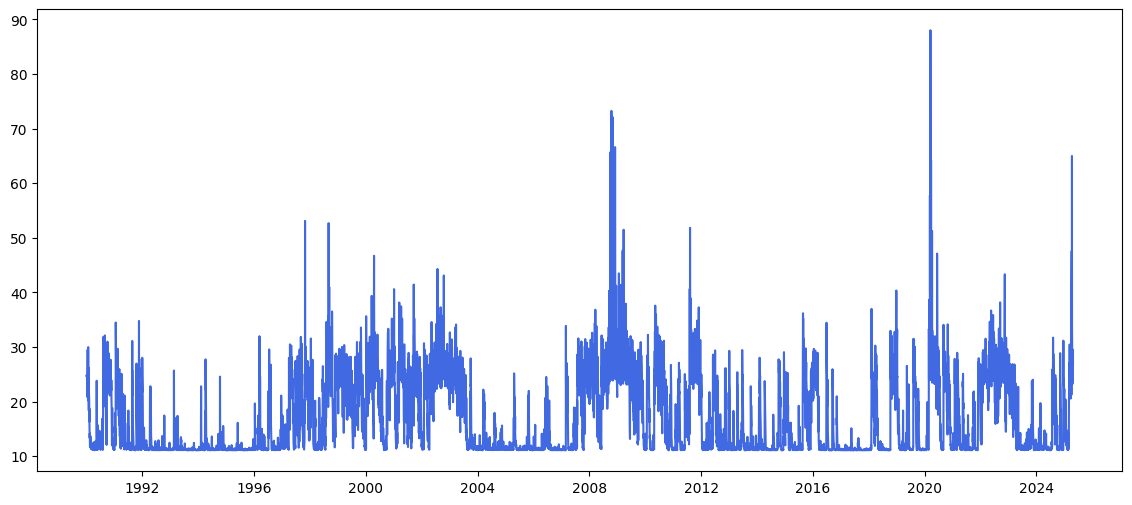

In [17]:
plot_model_vs_vix(stored_data, Sigma_backtest, target='SPX Index')




In [108]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
import numpy as np
from math import ceil

def plot_model_vs_vix_pdf(stored_data, sigma_dict, target='SPX Index', comparison_series='VIX Index', pdf_filename='volatility_vs_vix.pdf'):
    """
    Exports:
    - Big VIX vs SPX + X=None
    - Grid of model-only volatility plots
    - One-by-one large overlay plots (VIX vs each model)
    into a single multi-page PDF.
    """

    if target not in stored_data or target not in sigma_dict:
        print(f"❌ Target '{target}' not found in inputs.")
        return

    indicators = list(stored_data[target].keys())
    indicators = sorted(indicators, key=lambda x: (x != 'No Exogenous', x))  # 'No Exogenous' first

    with PdfPages(pdf_filename) as pdf:

        # --- A. Big Plot: VIX vs X=None ---
        base_result = stored_data[target].get('No Exogenous')
        base_sigma2 = sigma_dict[target].get('No Exogenous')

        if base_result is None or base_sigma2 is None:
            print("❌ Missing 'No Exogenous' model.")
            return

        base_dates = base_result['dates']
        base_vol = np.sqrt(base_sigma2) * np.sqrt(252)
        try:
            base_vix = data.loc[base_dates, comparison_series].values
        except Exception as e:
            print(f"❌ Could not extract VIX for 'No Exogenous': {e}")
            return

        plt.figure(figsize=(14, 6))
        plt.plot(base_dates, base_vol, label='Model Volatility (X = None)', linewidth=1.5, color='royalblue')
        plt.plot(base_dates, base_vix, label='VIX Index', linewidth=1.5, color='darkorange')
        plt.title("VIX vs SPX Index + X = None", fontsize=14)
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        pdf.savefig()
        plt.close()

        # --- B. Model-only Volatility Grid (No VIX) ---
        other_indicators = [ind for ind in indicators if ind != 'No Exogenous']
        n = len(other_indicators)
        if n > 0:
            ncols = 2
            nrows = ceil(n / ncols)

            fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
            axes = axes.flatten()

            for i, indicator in enumerate(other_indicators):
                dico = stored_data[target][indicator]
                sigma2 = sigma_dict[target].get(indicator)

                if sigma2 is None or np.isnan(sigma2).all():
                    axes[i].set_title(f"{indicator} — Skipped (NaNs)")
                    axes[i].axis('off')
                    continue

                vol = np.sqrt(sigma2) * np.sqrt(252)
                dates = dico['dates']

                axes[i].plot(dates, vol, label=f'X = {indicator}', linewidth=1.2, color='steelblue')
                axes[i].set_title(f'Model Volatility: X = {indicator}', fontsize=10)
                axes[i].grid(True)

            for j in range(i + 1, len(axes)):
                fig.delaxes(axes[j])

            fig.suptitle("Model Volatility Alone (Annualized, No VIX)", fontsize=14)
            plt.tight_layout(rect=[0, 0, 1, 0.96])
            pdf.savefig(fig)
            plt.close(fig)

        # --- C. VIX vs Each Model (Big Individual Pages) ---
        for indicator in other_indicators:
            dico = stored_data[target][indicator]
            sigma2 = sigma_dict[target].get(indicator)

            if sigma2 is None or np.isnan(sigma2).all():
                print(f"⚠️ Skipping {indicator} — sigma² invalid.")
                continue

            vol = np.sqrt(sigma2) * np.sqrt(252)
            dates = dico['dates']
            try:
                vix = data.loc[dates, comparison_series].values
            except Exception as e:
                print(f"❌ Could not get VIX for {indicator}: {e}")
                continue

            plt.figure(figsize=(14, 5))
            plt.plot(dates, vol, label='Model Volatility', linewidth=1.5, color='royalblue')
            plt.plot(dates, vix, label='VIX Index', linewidth=1.5, color='darkorange')
            plt.title(f"VIX vs {target} + X = {indicator}", fontsize=13)
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            pdf.savefig()
            plt.close()

    print(f"✅ PDF saved to: {pdf_filename}")


plot_model_vs_vix_pdf(stored_data, Sigma_backtest, target='SPX Index', pdf_filename='spx_vol_vs_vix.pdf')


✅ PDF saved to: spx_vol_vs_vix.pdf


In [ ]:
"""
if you call :
store = calibrate_and_store(
    data=data,
    targets=['SPX Index'],
    indicators=[['VIX Index'], ['Oil Index']],
    d=2, q=1,
    niter_HMM=100, niter_MS=100, niter_X=50,
    folder='ExampleRun',
    preprocessing_dict=None
)

You return :


store = {
  'SPX Index': {
    'No Exogenous': {
        'eps': np.array([...]),
        'dates': pd.DatetimeIndex([...]),
        'target': 'SPX Index',
        'indicator': 'No Exogenous',
        'initial_params': {...},
        'result': [...],  # list of intermediate parameter sets from EM
        'final_result': {...},  # final parameter dict
        'states sequence': np.array([...]),
    },

    'VIX Index': {
        'eps': np.array([...]),
        'dates': pd.DatetimeIndex([...]),
        'target': 'SPX Index',
        'indicator': 'VIX Index',
        'initial_params': {...},
        'result': [...],
        'final_result': {
            'sigma²': np.array([...]),
            'mu': np.array([...]),
            'beta': np.array([...]),
            'log-likelihood': ...,
            'mean log-likelihood': ...,
            'exogen_transition': np.array([...]),
            'exogen_additive': np.array([...]),
        },
        'states sequence': np.array([...]),
    },

    'Oil Index': {
        ...
    }
  }
}


store['SPX Index']['No Exogenous']['final_result']['sigma²']  # variance path
store['SPX Index']['VIX Index']['final_result']['mu']          # mu coefficients
store['SPX Index']['VIX Index']['states sequence']             # inferred regime path
store['SPX Index']['VIX Index']['dates']                       # aligned dates

"""